# Effect of two antihypertensive drugs on systolic blood pressure: a reproducible report

**Course:** BIT 4131 Statistical Computing and Reporting, Topic 23

This report is generated by code. Every number in the text is computed from the data
when the notebook runs, so re-running the notebook regenerates the whole report.
The data are **synthetic**, created for teaching, and the results say nothing about
real drugs.

**Question:** Do Drug A and Drug B lower systolic blood pressure (SBP) more than the
control after 12 weeks, and does Drug B work better than Drug A?

## 1. Setup and reproducibility record

In [1]:
import hashlib
import json
import platform
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import statsmodels
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multitest import multipletests

SEED = 2024
DATA, OUT = Path("data"), Path("outputs")
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
key = {}  # key numbers saved at the end

env = {
    "python": sys.version.split()[0], "platform": platform.platform(),
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "statsmodels": statsmodels.__version__, "matplotlib": matplotlib.__version__,
    "random seed": SEED,
}
for k, v in env.items():
    print(f"{k:12s}: {v}")
(OUT / "session_info.txt").write_text("\n".join(f"{k}: {v}" for k, v in env.items()))

python      : 3.13.14
platform    : Windows-11-10.0.26300-SP0
numpy       : 2.5.4
pandas      : 3.0.6
scipy       : 1.18.1
statsmodels : 0.15.0
matplotlib  : 3.11.2
random seed : 2024


149

## 2. Data

In [2]:
N_PER = 80
ARMS = ["Control", "Drug A", "Drug B"]
TRUE_EFFECT = {"Control": 0.0, "Drug A": -6.0, "Drug B": -10.0}
DROPOUT = {"Control": 0.06, "Drug A": 0.08, "Drug B": 0.12}


def make_data(seed=SEED):
    """Generate the trial data. The same seed always gives the same data."""
    r = np.random.default_rng(seed)
    n = N_PER * 3
    arm = np.repeat(ARMS, N_PER)
    age = r.normal(55, 10, n).clip(30, 80).round()
    sex = np.where(r.random(n) < 0.5, "F", "M")
    base = r.normal(150, 12, n).round(1)
    change = (-3 + np.array([TRUE_EFFECT[a] for a in arm]) - 0.25 * (base - 150)
              + 0.05 * (age - 55) + r.normal(0, 9, n))
    week12 = (base + change).round(1)
    dropped = r.random(n) < np.array([DROPOUT[a] for a in arm])
    week12 = np.where(dropped, np.nan, week12)
    return pd.DataFrame({"id": np.arange(1, n + 1), "arm": arm, "age": age, "sex": sex,
                         "baseline_sbp": base, "week12_sbp": week12})


def file_hash(frame):
    return hashlib.sha256(frame.to_csv(index=False).encode()).hexdigest()


df = make_data()
df.to_csv(DATA / "trial_data.csv", index=False)
h1, h2 = file_hash(df), file_hash(make_data())
print(f"SHA-256 of the data file: {h1[:16]}...")
print("Regenerating with the same seed gives an identical file:", h1 == h2)
assert h1 == h2
df.head()

SHA-256 of the data file: c1f7458ea07942b8...
Regenerating with the same seed gives an identical file: True


,id,arm,age,sex,baseline_sbp,week12_sbp
0,1,Control,65.0,F,171.7,177.1
1,2,Control,71.0,F,155.9,144.6
2,3,Control,66.0,M,155.3,173.0
3,4,Control,45.0,F,133.6,129.8
4,5,Control,41.0,F,162.7,145.9


### 2.1 Data checks

In [3]:
df["change"] = df["week12_sbp"] - df["baseline_sbp"]
df["female"] = (df["sex"] == "F").astype(int)
print(f"Rows = {len(df)}, columns = {df.shape[1]}, duplicated ids = {df['id'].duplicated().sum()}")
print(f"Age range {df['age'].min():.0f} to {df['age'].max():.0f}; baseline SBP range "
      f"{df['baseline_sbp'].min():.1f} to {df['baseline_sbp'].max():.1f}")
assert df["id"].is_unique
assert df["age"].between(18, 100).all()
assert df["baseline_sbp"].between(80, 220).all()
miss = df["week12_sbp"].isna()
print(f"Missing week-12 outcomes: {miss.sum()} of {len(df)} ({miss.mean():.1%})")
dropout = pd.crosstab(df["arm"], miss).loc[ARMS]
dropout.columns = ["observed", "missing"]
chi = stats.chi2_contingency(dropout.to_numpy())
print(dropout.to_string())
print(f"Chi-square test of dropout against arm: p = {chi[1]:.3f}")
key["n_total"] = int(len(df))
key["n_missing"] = int(miss.sum())
key["dropout_p"] = float(chi[1])

Rows = 240, columns = 8, duplicated ids = 0
Age range 30 to 79; baseline SBP range 109.8 to 185.9
Missing week-12 outcomes: 24 of 240 (10.0%)
         observed  missing
arm                       
Control        78        2
Drug A         72        8
Drug B         66       14
Chi-square test of dropout against arm: p = 0.007


### 2.2 Table 1: baseline characteristics by arm

In [4]:
g = df.groupby("arm")
t1 = pd.DataFrame({
    "n": g.size(),
    "age_mean": g["age"].mean(), "age_sd": g["age"].std(),
    "female_pct": g["female"].mean() * 100,
    "baseline_mean": g["baseline_sbp"].mean(), "baseline_sd": g["baseline_sbp"].std(),
    "missing_outcome_n": g["week12_sbp"].apply(lambda s: int(s.isna().sum())),
}).loc[ARMS]
t1["missing_outcome_pct"] = t1["missing_outcome_n"] / t1["n"] * 100
t1.round(3).to_csv(OUT / "table1_baseline.csv")

p_age = stats.f_oneway(*[df.loc[df["arm"] == a, "age"] for a in ARMS]).pvalue
p_base = stats.f_oneway(*[df.loc[df["arm"] == a, "baseline_sbp"] for a in ARMS]).pvalue
p_sex = stats.chi2_contingency(pd.crosstab(df["arm"], df["sex"]).to_numpy())[1]
print(f"Balance tests across arms: age p = {p_age:.3f}, baseline SBP p = {p_base:.3f}, "
      f"sex p = {p_sex:.3f}")
key["balance_p"] = {"age": float(p_age), "baseline": float(p_base), "sex": float(p_sex)}
t1

Balance tests across arms: age p = 0.720, baseline SBP p = 0.653, sex p = 0.659


,n,age_mean,age_sd,female_pct,baseline_mean,baseline_sd,missing_outcome_n,missing_outcome_pct
arm,,,,,,,,
Control,80,55.538,9.114,52.50,150.219,13.241,2,2.5
Drug A,80,54.450,9.837,52.50,150.853,11.708,8,10.0
Drug B,80,54.450,10.389,46.25,149.029,12.987,14,17.5


## 3. Outcome by arm

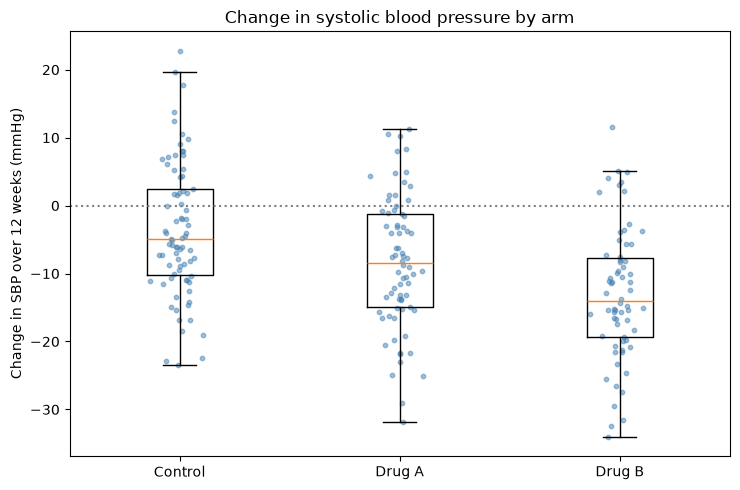

,n,mean_change,sd,se
arm,,,,
Control,78,-3.591,9.825,1.112
Drug A,72,-8.324,9.689,1.142
Drug B,66,-12.950,9.714,1.196


In [5]:
dc = df.dropna(subset=["change"]).copy()
dc["drugA"] = (dc["arm"] == "Drug A").astype(int)
dc["drugB"] = (dc["arm"] == "Drug B").astype(int)

gc = dc.groupby("arm")["change"]
by_arm = pd.DataFrame({"n": gc.size(), "mean_change": gc.mean(), "sd": gc.std()}).loc[ARMS]
by_arm["se"] = by_arm["sd"] / np.sqrt(by_arm["n"])
by_arm.round(3).to_csv(OUT / "outcome_by_arm.csv")

ctrl = dc.loc[dc["arm"] == "Control", "change"]
cohen = {}
for a in ["Drug A", "Drug B"]:
    x = dc.loc[dc["arm"] == a, "change"]
    sp = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(ctrl) - 1) * ctrl.var(ddof=1))
                 / (len(x) + len(ctrl) - 2))
    cohen[a] = (x.mean() - ctrl.mean()) / sp
key["cohen_d_unadjusted"] = {k: float(v) for k, v in cohen.items()}

fig, ax = plt.subplots(figsize=(7.5, 5))
data_ = [dc.loc[dc["arm"] == a, "change"] for a in ARMS]
ax.boxplot(data_, tick_labels=ARMS, showfliers=False)
for i, d in enumerate(data_, start=1):
    ax.scatter(np.random.default_rng(1).normal(i, 0.05, len(d)), d, s=10, alpha=0.5,
               color="steelblue")
ax.axhline(0, color="grey", linestyle=":")
ax.set_ylabel("Change in SBP over 12 weeks (mmHg)")
ax.set_title("Change in systolic blood pressure by arm")
fig.tight_layout()
fig.savefig(OUT / "figure1_change_by_arm.png", dpi=150)
plt.show()
by_arm

## 4. Primary analysis: adjusted regression

In [6]:
formula = "change ~ drugA + drugB + baseline_sbp + age + female"
model = smf.ols(formula, data=dc).fit()
ci = model.conf_int()
names = {"drugA": "Drug A vs Control", "drugB": "Drug B vs Control"}
p_raw = [model.pvalues["drugA"], model.pvalues["drugB"]]
p_holm = multipletests(p_raw, method="holm")[1]
res = {}
for (term, label), ph in zip(names.items(), p_holm):
    res[label] = {"est": float(model.params[term]), "lo": float(ci.loc[term, 0]),
                  "hi": float(ci.loc[term, 1]), "p": float(model.pvalues[term]),
                  "p_holm": float(ph)}
contrast = model.t_test("drugB - drugA = 0")
res["Drug B vs Drug A"] = {
    "est": float(np.squeeze(contrast.effect)),
    "lo": float(np.squeeze(contrast.conf_int())[0]),
    "hi": float(np.squeeze(contrast.conf_int())[1]),
    "p": float(np.squeeze(contrast.pvalue)), "p_holm": float("nan")}

tab = pd.DataFrame(res).T
tab.round(5).to_csv(OUT / "table2_treatment_effects.csv")
cov_tab = pd.DataFrame({"coef": model.params, "se": model.bse, "p": model.pvalues,
                        "lo": ci[0], "hi": ci[1]})
cov_tab.round(5).to_csv(OUT / "table3_regression_coefficients.csv")
print(f"Complete cases analysed: {int(model.nobs)}; R-squared = {model.rsquared:.3f}; "
      f"residual SE = {np.sqrt(model.scale):.2f}")
key.update({"n_analysed": int(model.nobs), "r2": float(model.rsquared),
            "effects": res})
display(tab.round(4))
cov_tab.round(4)

Complete cases analysed: 216; R-squared = 0.273; residual SE = 8.99


,est,lo,hi,p,p_holm
Drug A vs Control,-4.377,-7.277,-1.478,3.300e-03,0.003
Drug B vs Control,-9.634,-12.603,-6.665,0.000e+00,0.000
Drug B vs Drug A,-5.257,-8.287,-2.226,8.000e-04,NaN


,coef,se,p,lo,hi
Intercept,25.948,8.510,0.003,9.172,42.724
drugA,-4.377,1.471,0.003,-7.277,-1.478
drugB,-9.634,1.506,0.000,-12.603,-6.665
baseline_sbp,-0.264,0.049,0.000,-0.362,-0.167
age,0.179,0.062,0.004,0.057,0.301
female,0.480,1.229,0.696,-1.942,2.903


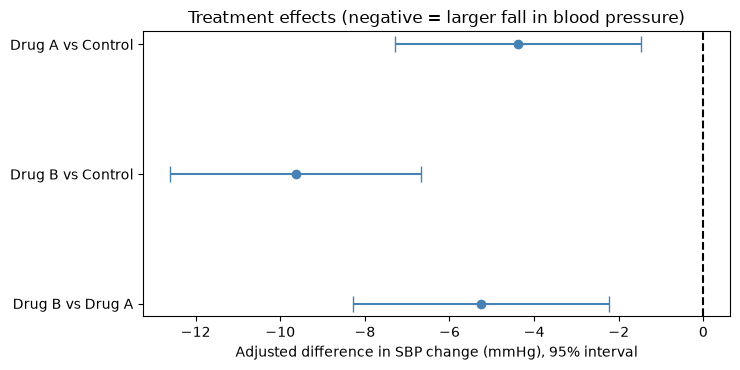

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
labels = list(res)
for i, lab in enumerate(labels[::-1]):
    r_ = res[lab]
    ax.errorbar(r_["est"], i, xerr=[[r_["est"] - r_["lo"]], [r_["hi"] - r_["est"]]],
                fmt="o", capsize=6, color="steelblue")
ax.axvline(0, color="black", linestyle="--")
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels[::-1])
ax.set_xlabel("Adjusted difference in SBP change (mmHg), 95% interval")
ax.set_title("Treatment effects (negative = larger fall in blood pressure)")
fig.tight_layout()
fig.savefig(OUT / "figure2_treatment_effects.png", dpi=150)
plt.show()

## 5. Sensitivity analyses and model checks

Shapiro-Wilk on residuals: W = 0.9912, p = 0.2182
Breusch-Pagan: LM = 1.742, p = 0.8836


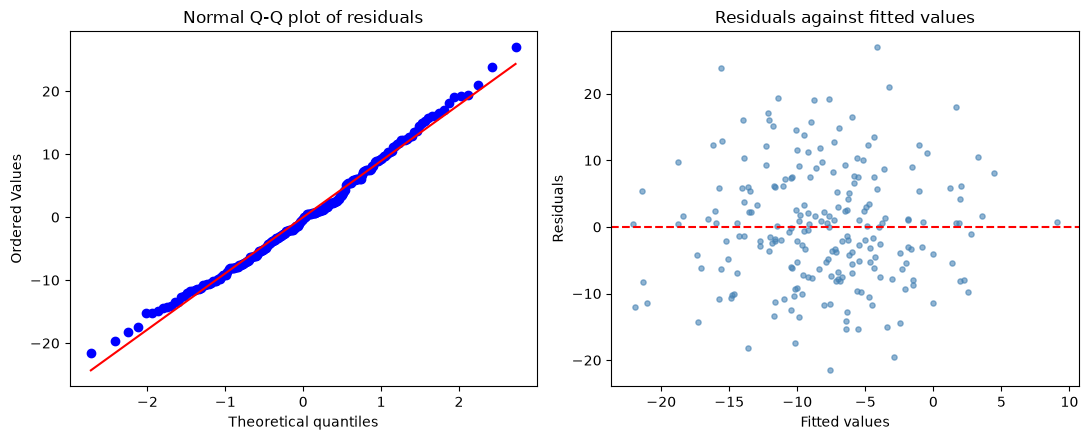

,Drug A: estimate,Drug A: SE,Drug B: estimate,Drug B: SE
Adjusted (primary),-4.377,1.471,-9.634,1.506
Unadjusted,-4.733,1.593,-9.359,1.630
"Adjusted, robust (HC3) errors",-4.377,1.519,-9.634,1.470


In [8]:
unadj = smf.ols("change ~ drugA + drugB", data=dc).fit()
robust = smf.ols(formula, data=dc).fit(cov_type="HC3")
sens = pd.DataFrame({
    "Drug A: estimate": [model.params["drugA"], unadj.params["drugA"], robust.params["drugA"]],
    "Drug A: SE": [model.bse["drugA"], unadj.bse["drugA"], robust.bse["drugA"]],
    "Drug B: estimate": [model.params["drugB"], unadj.params["drugB"], robust.params["drugB"]],
    "Drug B: SE": [model.bse["drugB"], unadj.bse["drugB"], robust.bse["drugB"]],
}, index=["Adjusted (primary)", "Unadjusted", "Adjusted, robust (HC3) errors"])
sens.round(4).to_csv(OUT / "table4_sensitivity.csv")

resid = model.resid
sw = stats.shapiro(resid)
bp = het_breuschpagan(resid, model.model.exog)
print(f"Shapiro-Wilk on residuals: W = {sw.statistic:.4f}, p = {sw.pvalue:.4f}")
print(f"Breusch-Pagan: LM = {bp[0]:.3f}, p = {bp[1]:.4f}")
key["shapiro_p"] = float(sw.pvalue)
key["breusch_pagan_p"] = float(bp[1])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
stats.probplot(resid, dist="norm", plot=axes[0])
axes[0].set_title("Normal Q-Q plot of residuals")
axes[1].scatter(model.fittedvalues, resid, s=14, alpha=0.6, color="steelblue")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Fitted values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals against fitted values")
fig.tight_layout()
fig.savefig(OUT / "figure3_diagnostics.png", dpi=150)
plt.show()
sens

## 6. Results (text generated from the numbers above)

In [9]:
A, B, AB = res["Drug A vs Control"], res["Drug B vs Control"], res["Drug B vs Drug A"]
n_by = by_arm["n"].astype(int).to_dict()
sig = lambda p: "statistically significant" if p < 0.05 else "not statistically significant"
drop_txt = "differed" if key["dropout_p"] < 0.05 else "did not differ clearly"
fmt_p = lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"

report = f"""
**Participants.** {key['n_total']} patients were randomised equally to three arms. The
week-12 outcome was missing for {key['n_missing']} patients ({key['n_missing'] / key['n_total']:.1%}),
so {key['n_analysed']} were analysed (Control {n_by['Control']}, Drug A {n_by['Drug A']},
Drug B {n_by['Drug B']}). Dropout {drop_txt} between arms
(chi-square p = {fmt_p(key['dropout_p'])}).
Baseline age, sex and blood pressure were balanced across arms (p = {fmt_p(key['balance_p']['age'])},
{fmt_p(key['balance_p']['sex'])} and {fmt_p(key['balance_p']['baseline'])}).

**Primary analysis.** After adjusting for baseline blood pressure, age and sex, Drug A lowered
SBP by **{abs(A['est']):.1f} mmHg** more than control (95% CI {A['lo']:.1f} to {A['hi']:.1f};
Holm-adjusted p {fmt_p(A['p_holm'])}), which is {sig(A['p_holm'])}. Drug B lowered SBP by
**{abs(B['est']):.1f} mmHg** more than control (95% CI {B['lo']:.1f} to {B['hi']:.1f};
Holm-adjusted p {fmt_p(B['p_holm'])}), which is {sig(B['p_holm'])}. Drug B lowered SBP by a further
**{abs(AB['est']):.1f} mmHg** compared with Drug A (95% CI {AB['lo']:.1f} to {AB['hi']:.1f};
p {fmt_p(AB['p'])}, unadjusted for multiplicity), which is {sig(AB['p'])}.

**Effect sizes.** Unadjusted standardised differences from control were d = {key['cohen_d_unadjusted']['Drug A']:.2f}
for Drug A and d = {key['cohen_d_unadjusted']['Drug B']:.2f} for Drug B (negative = larger fall).
The model explains {key['r2']:.1%} of the variation in change.

**Model checks.** The residuals were consistent with normality (Shapiro-Wilk p = {fmt_p(key['shapiro_p'])})
and constant variance (Breusch-Pagan p = {fmt_p(key['breusch_pagan_p'])}) if those p-values are above 0.05.
The unadjusted and robust-error analyses (Table 4) give estimates and standard errors close to the primary analysis.
"""
display(Markdown(report))
(OUT / "results_text.md").write_text(report)


**Participants.** 240 patients were randomised equally to three arms. The
week-12 outcome was missing for 24 patients (10.0%),
so 216 were analysed (Control 78, Drug A 72,
Drug B 66). Dropout differed between arms
(chi-square p = 0.007).
Baseline age, sex and blood pressure were balanced across arms (p = 0.720,
0.659 and 0.653).

**Primary analysis.** After adjusting for baseline blood pressure, age and sex, Drug A lowered
SBP by **4.4 mmHg** more than control (95% CI -7.3 to -1.5;
Holm-adjusted p 0.003), which is statistically significant. Drug B lowered SBP by
**9.6 mmHg** more than control (95% CI -12.6 to -6.7;
Holm-adjusted p < 0.001), which is statistically significant. Drug B lowered SBP by a further
**5.3 mmHg** compared with Drug A (95% CI -8.3 to -2.2;
p < 0.001, unadjusted for multiplicity), which is statistically significant.

**Effect sizes.** Unadjusted standardised differences from control were d = -0.48
for Drug A and d = -0.96 for Drug B (negative = larger fall).
The model explains 27.3% of the variation in change.

**Model checks.** The residuals were consistent with normality (Shapiro-Wilk p = 0.218)
and constant variance (Breusch-Pagan p = 0.884) if those p-values are above 0.05.
The unadjusted and robust-error analyses (Table 4) give estimates and standard errors close to the primary analysis.


1337

## 7. Limitations

- The data are synthetic, so the results illustrate a method and carry no clinical meaning.
- The primary analysis uses complete cases. If dropout depends on the outcome, the estimates could be biased. Topic 22 shows how multiple imputation and sensitivity analysis address this.
- The Drug B versus Drug A comparison was not adjusted for multiplicity, because only the two comparisons with control were treated as primary.
- Follow-up was a single time point. A real trial would also report adverse events.

## 8. Conclusion and reproducibility

In [10]:
better = "Drug B" if abs(res["Drug B vs Control"]["est"]) > abs(res["Drug A vs Control"]["est"]) else "Drug A"
display(Markdown(f"""
Both drugs lowered blood pressure relative to control in this simulated trial, and **{better}** had the
larger effect. The analysis is fully reproducible: running `build_report.py` with the same package versions
and seed regenerates the data (hash `{h1[:16]}...`), every table, every figure and every number in the text.
"""))
key["data_hash"] = h1
with open(OUT / "key_numbers.json", "w") as fh:
    json.dump(key, fh, indent=2)
print("Files written to", OUT.resolve())
for f in sorted(OUT.iterdir()):
    print(" ", f.name)


Both drugs lowered blood pressure relative to control in this simulated trial, and **Drug B** had the
larger effect. The analysis is fully reproducible: running `build_report.py` with the same package versions
and seed regenerates the data (hash `c1f7458ea07942b8...`), every table, every figure and every number in the text.


Files written to D:\statistical-computing\topic_23_reproducible_reporting\outputs
  console_output.txt
  figure1_change_by_arm.png
  figure2_treatment_effects.png
  figure3_diagnostics.png
  key_numbers.json
  outcome_by_arm.csv
  report.html
  results_text.md
  session_info.txt
  table1_baseline.csv
  table2_treatment_effects.csv
  table3_regression_coefficients.csv
  table4_sensitivity.csv
